### **Load LVIS Data**

In [29]:
import json
import pandas as pd

# Load LVIS v1 validation annotations
with open("..\..\..\ml\data\lvis_v1_train.json", "r", encoding="utf-8") as f:
    lvis_data = json.load(f)

# Inspect top-level dictionary keys
print(lvis_data.keys())

# Convert core tables into DataFrames
images_df = pd.DataFrame(lvis_data["images"])
annotations_df = pd.DataFrame(lvis_data["annotations"])
categories_df = pd.DataFrame(lvis_data["categories"])

images_df


<>:5: SyntaxWarning: invalid escape sequence '\.'
<>:5: SyntaxWarning: invalid escape sequence '\.'
C:\Users\exe\AppData\Local\Temp\ipykernel_23396\2878059049.py:5: SyntaxWarning: invalid escape sequence '\.'
  with open("..\..\..\ml\data\lvis_v1_train.json", "r", encoding="utf-8") as f:


dict_keys(['info', 'annotations', 'images', 'licenses', 'categories'])


,flickr_url,id,neg_category_ids,not_exhaustive_category_ids,width,license,coco_url,date_captured,height
0,http://farm9.staticflickr.com/8186/8119368305_...,391895,"[475, 322, 1024, 412, 256, 966, 98, 131, 1111,...",[],640,3,http://images.cocodataset.org/train2017/000000...,2013-11-14 11:18:45,360
1,http://farm1.staticflickr.com/1/127244861_ab0c...,522418,"[1022, 498, 345, 171, 36, 37, 701, 526, 1038, ...",[],640,4,http://images.cocodataset.org/train2017/000000...,2013-11-14 11:38:44,480
2,http://farm3.staticflickr.com/2169/2118578392_...,184613,"[1069, 74, 1004, 419, 484, 1106, 98, 423, 771,...","[947, 80]",500,3,http://images.cocodataset.org/train2017/000000...,2013-11-14 12:36:29,336
3,http://farm5.staticflickr.com/4125/5094763076_...,318219,"[280, 346, 51, 404, 904, 202, 398, 576, 1036, ...",[],556,3,http://images.cocodataset.org/train2017/000000...,2013-11-14 13:02:53,640
4,http://farm5.staticflickr.com/4086/5094162993_...,554625,"[650, 500, 1072, 105, 27, 28, 79, 505, 544, 61...",[698],426,3,http://images.cocodataset.org/train2017/000000...,2013-11-14 16:03:19,640
...,...,...,...,...,...,...,...,...,...
100165,http://farm4.staticflickr.com/3697/9303670993_...,444010,"[1071, 218, 1048, 6, 931, 465, 489, 15, 647, 341]",[],640,1,http://images.cocodataset.org/train2017/000000...,2013-11-25 14:46:11,480
100166,http://farm2.staticflickr.com/1278/4677568591_...,565004,"[877, 1189, 955, 974, 748, 536, 962]",[139],640,3,http://images.cocodataset.org/train2017/000000...,2013-11-25 19:59:30,427
100167,http://farm3.staticflickr.com/2379/2293730995_...,516168,"[1068, 23, 868, 1078, 131, 725, 403, 89, 976]",[],640,3,http://images.cocodataset.org/train2017/000000...,2013-11-25 21:03:34,480
100168,http://farm1.staticflickr.com/178/423174638_1c...,547503,"[900, 199, 130, 1129, 34, 725, 775, 142]",[782],500,4,http://images.cocodataset.org/train2017/000000...,2013-11-25 21:20:21,375


### **Cleaning - Transformation - Merging**

In [30]:
# Keep only images that have at least one annotated object
images_df = images_df[images_df["id"].isin(annotations_df["image_id"])]


In [31]:
# Rename 'id' to 'image_id' and index for join
images_df = images_df.rename(columns={"id": "image_id"}, errors="ignore").set_index("image_id")

# Merge image metadata (dimensions, URLs) into annotations table
annotations_df = annotations_df.join(images_df, on="image_id", how="left").drop(columns=["id"], errors="ignore").sort_values(by=["image_id"])
annotations_df.head()


,bbox,category_id,image_id,segmentation,area,flickr_url,neg_category_ids,not_exhaustive_category_ids,width,license,coco_url,date_captured,height
964512,"[241.72, 155.05, 166.37, 195.45]",1139,30,"[[335.88, 350.5, 355.88, 349.04, 367.59, 346.6...",16152.80,http://farm4.staticflickr.com/3377/3573516590_...,"[416, 675, 488, 724, 1064, 1092]",[],640,4,http://images.cocodataset.org/train2017/000000...,2013-11-24 03:32:32,428
964511,"[203.85, 34.64, 255.15, 187.77]",461,30,"[[244.45, 185.69, 237.8, 184.29, 233.95, 186.3...",29730.64,http://farm4.staticflickr.com/3377/3573516590_...,"[416, 675, 488, 724, 1064, 1092]",[],640,4,http://images.cocodataset.org/train2017/000000...,2013-11-24 03:32:32,428
868251,"[0.0, 20.56, 437.95, 383.73]",1202,34,"[[294.27, 288.43, 290.81, 306.87, 290.52, 324....",92650.94,http://farm5.staticflickr.com/4024/4599442031_...,"[1102, 1007, 745, 1177, 42, 212, 118, 1182, 18]",[],640,6,http://images.cocodataset.org/train2017/000000...,2013-11-18 16:32:48,425
1047832,"[313.54, 305.71, 51.16, 88.32]",1023,36,"[[313.54, 305.71, 314.65, 308.18, 321.67, 321....",503.55,http://farm8.staticflickr.com/7216/7200825264_...,"[963, 922, 1165, 903, 989, 86, 117]",[],481,3,http://images.cocodataset.org/train2017/000000...,2013-11-18 06:56:10,640
1047827,"[253.4, 309.65, 63.9, 39.23]",715,36,"[[288.39, 345.1, 286.09, 343.95, 284.61, 343.1...",163.71,http://farm8.staticflickr.com/7216/7200825264_...,"[963, 922, 1165, 903, 989, 86, 117]",[],481,3,http://images.cocodataset.org/train2017/000000...,2013-11-18 06:56:10,640


In [32]:
categories_df = categories_df.rename(columns={"id": "category_id"}, errors="ignore").set_index("category_id")

annotations_df = annotations_df.join(categories_df, on="category_id", how="left")

In [33]:
df = annotations_df.copy()

### **Stratifying**

#### **Analysis**

on : area, height, width, category, number of segmentations in 1 image

##### **Scene Cleariness (number of segmentations in 1 image)**

<Axes: xlabel='count', ylabel='Density'>

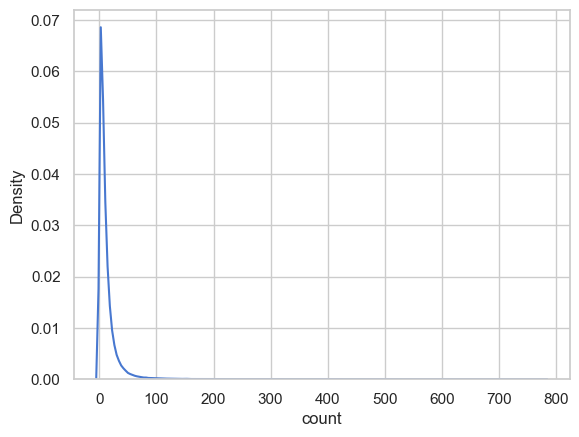

In [34]:
import seaborn as sb

sb.kdeplot(data=df["image_id"].value_counts())

##### **Area**

<Axes: xlabel='area', ylabel='Density'>

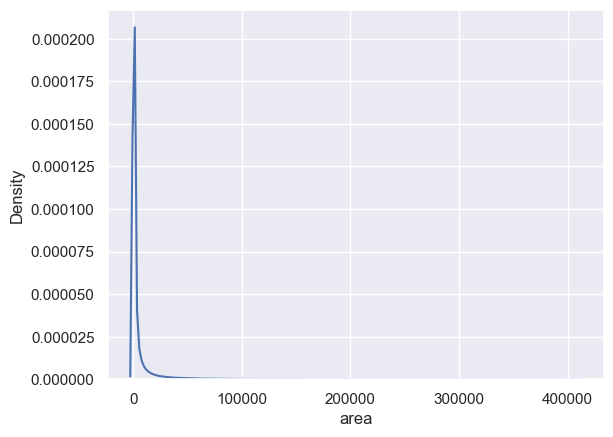

In [35]:
import seaborn as sb
sb.set_theme()

sb.kdeplot(data=df, x="area")

In [36]:
def area_segm(area):
    if area < 32**2: return "small"
    elif area > 32**2 and area < 96**2: return "medium"
    else: return "large"

df["area_category"] = df["area"].apply(area_segm)

In [37]:
df["area_category"]

964512      large
964511      large
868251      large
1047832     small
1047827     small
            ...  
310000      small
309998      small
309999     medium
190476      large
190477     medium
Name: area_category, Length: 1270141, dtype: object

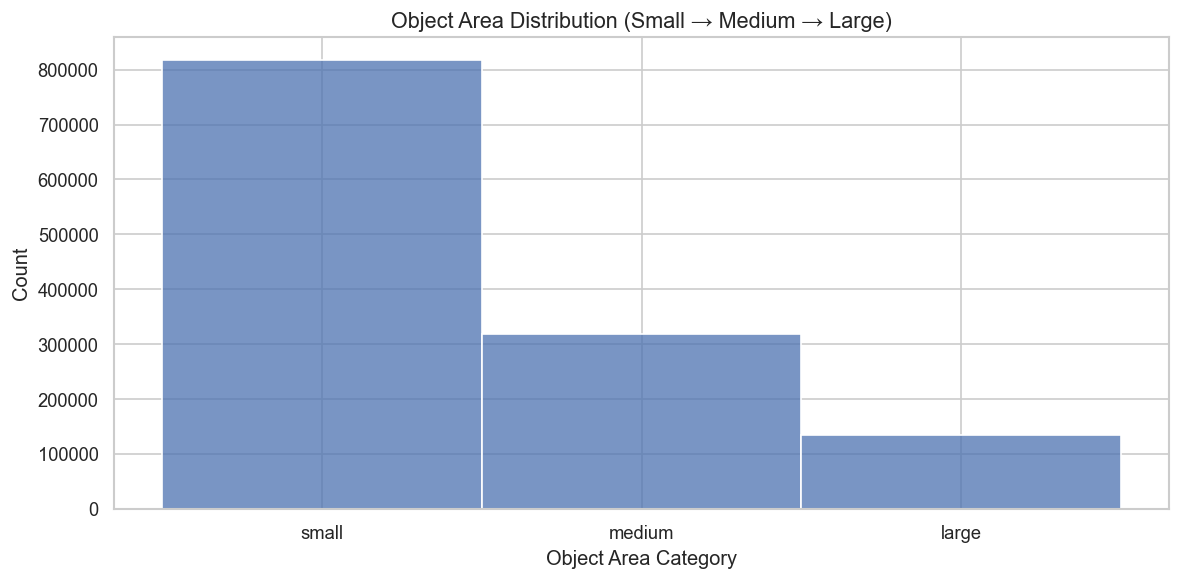

In [38]:
import matplotlib.pyplot as plt
import pandas as pd

sb.set_theme(style="whitegrid")

order = ["small", "medium", "large"]

plot_df = df.copy()
plot_df["area_category"] = pd.Categorical(
    plot_df["area_category"], categories=order, ordered=True
)

plt.figure(figsize=(10, 5), dpi=120)
ax = sb.histplot(data=plot_df, x="area_category", discrete=True)

ax.set_xlabel("Object Area Category", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.set_title("Object Area Distribution (Small → Medium → Large)", fontsize=13)

plt.tight_layout()
plt.show()

##### **Height / Width of image**

In [39]:
df["image_pixel_count"] = df["width"] * df["height"]
df.head(3)

,bbox,category_id,image_id,segmentation,area,flickr_url,neg_category_ids,not_exhaustive_category_ids,width,license,...,height,name,instance_count,def,synonyms,image_count,frequency,synset,area_category,image_pixel_count
964512,"[241.72, 155.05, 166.37, 195.45]",1139,30,"[[335.88, 350.5, 355.88, 349.04, 367.59, 346.6...",16152.80,http://farm4.staticflickr.com/3377/3573516590_...,"[416, 675, 488, 724, 1064, 1092]",[],640,4,...,428,vase,4971,an open jar of glass or porcelain used as an o...,[vase],1866,f,vase.n.01,large,273920
964511,"[203.85, 34.64, 255.15, 187.77]",461,30,"[[244.45, 185.69, 237.8, 184.29, 233.95, 186.3...",29730.64,http://farm4.staticflickr.com/3377/3573516590_...,"[416, 675, 488, 724, 1064, 1092]",[],640,4,...,428,flower_arrangement,3960,a decorative arrangement of flowers,"[flower_arrangement, floral_arrangement]",1779,f,flower_arrangement.n.01,large,273920
868251,"[0.0, 20.56, 437.95, 383.73]",1202,34,"[[294.27, 288.43, 290.81, 306.87, 290.52, 324....",92650.94,http://farm5.staticflickr.com/4024/4599442031_...,"[1102, 1007, 745, 1177, 42, 212, 118, 1182, 18]",[],640,6,...,425,zebra,5443,any of several fleet black-and-white striped A...,[zebra],1674,f,zebra.n.01,large,272000


<Axes: xlabel='image_pixel_count', ylabel='Density'>

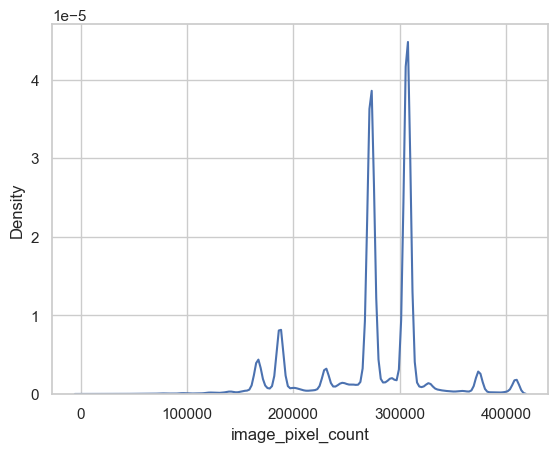

In [40]:
sb.kdeplot(data=df, x="image_pixel_count")

<Axes: xlabel='width', ylabel='height'>

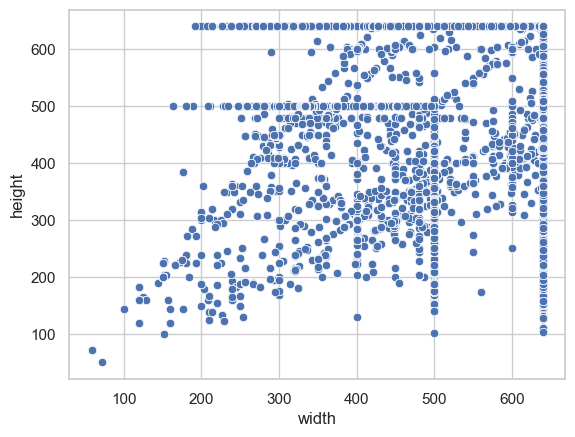

In [41]:
sb.scatterplot(data=df, x="width", y="height")

<Axes: xlabel='width'>

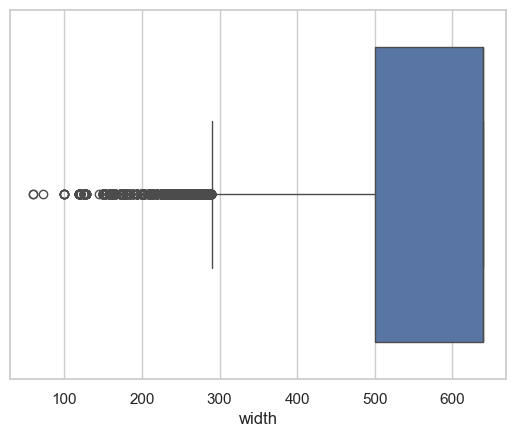

In [42]:
sb.boxplot(data=df, x="width")

<Axes: xlabel='height'>

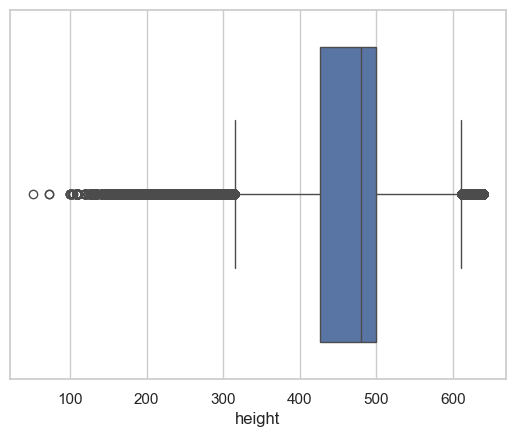

In [43]:
sb.boxplot(data=df, x="height")

<Axes: xlabel='aspect_ratio', ylabel='Density'>

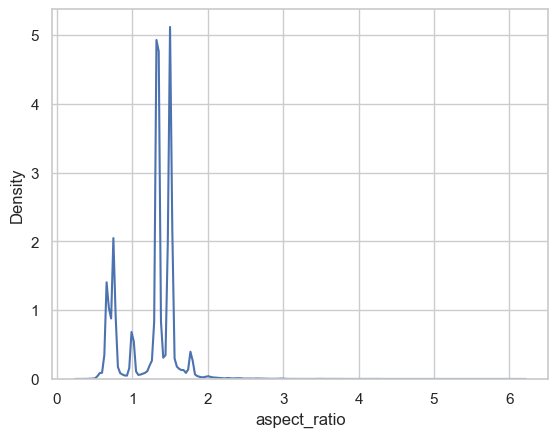

In [44]:
df["aspect_ratio"] = df["width"] / df["height"]
sb.kdeplot(data=df, x="aspect_ratio")

##### **Category**

<Axes: xlabel='count', ylabel='Density'>

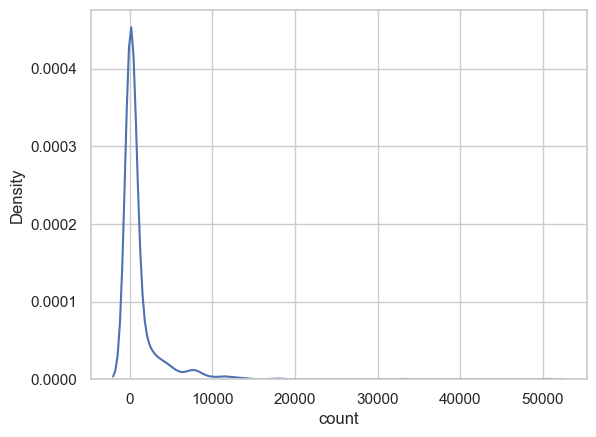

In [45]:
sb.kdeplot(data=df["name"].value_counts())

In [46]:
import ast
import nltk
from nltk.corpus import wordnet as wn
import pandas as pd

# Download required WordNet data once if not already cached
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)


# ---------------------------------------------------------------------------
# 1. Define 12 Target Categories (11 broad WordNet buckets + 'other')
# ---------------------------------------------------------------------------
TARGET_SYNSET_GROUPS = {
    "person": {"person.n.01", "causal_agent.n.01"},
    "vehicles": {"vehicle.n.01", "craft.n.02", "conveyance.n.03"},
    "animals": {
        "animal.n.01",
        "fauna.n.01",
        "vertebrate.n.01",
        "invertebrate.n.01",
    },
    "clothing_accessories": {
        "clothing.n.01",
        "garment.n.01",
        "wearable.n.01",
        "accessory.n.02",
        "footwear.n.01",
        "headgear.n.01",
        "jewelry.n.01",
        "fabric.n.01",
    },
    "furniture_home": {
        "furnishing.n.02",
        "furniture.n.01",
        "appliance.n.02",
        "room.n.01",
        "home_appliance.n.01",
        "household_equipment.n.01",
    },
    "kitchen_food": {
        "food.n.01",
        "dish.n.02",
        "tableware.n.01",
        "cookware.n.01",
        "beverage.n.01",
        "kitchen_utensil.n.01",
        "produce.n.01",
        "nutriment.n.01",
    },
    "electronics": {
        "electronic_equipment.n.01",
        "computer.n.01",
        "display.n.06",
        "camera.n.01",
        "device.n.01",
        "hardware.n.03",
    },
    "tools_sports_outdoor": {
        "tool.n.01",
        "implement.n.01",
        "equipment.n.01",
        "game_equipment.n.01",
        "sports_equipment.n.01",
        "weapon.n.01",
    },
    "plants_nature": {
        "plant.n.02",
        "flora.n.01",
        "geological_formation.n.01",
        "body_of_water.n.01",
        "natural_phenomenon.n.01",
        "matter.n.03",
    },
    "buildings_structures": {
        "structure.n.01",
        "building.n.01",
        "way.n.06",
        "barrier.n.01",
        "construction.n.01",
        "housing.n.01",
    },
    "text_signs_media": {
        "publication.n.01",
        "sign.n.02",
        "written_communication.n.01",
        "picture.n.01",
        "clock.n.01",
        "instrument.n.01",
        "container.n.01",
    },
    "other": set(),  # 12th bucket
}

assert len(TARGET_SYNSET_GROUPS) == 12, "Must have exactly 12 categories."

# Resolve target synsets safely (in case a WordNet version omits a specific synset)
resolved_targets = {}
for bucket, syn_names in TARGET_SYNSET_GROUPS.items():
  syns = set()
  for name in syn_names:
    try:
      syns.add(wn.synset(name))
    except Exception:
      pass
  resolved_targets[bucket] = syns

BUCKET_ANCHORS = {
    bucket: list(syns) for bucket, syns in resolved_targets.items() if syns
}
ALL_ANCHORS = [a for anchors in BUCKET_ANCHORS.values() for a in anchors]


# ---------------------------------------------------------------------------
# 2. Synset Parser & Similarity / Mapping Functions
# ---------------------------------------------------------------------------
def parse_synset(val):
  """Convert a synset string (e.g. 'dog.n.01'), list/stringified list, or lemma into a WordNet Synset."""
  if val is None or (isinstance(val, float) and pd.isna(val)):
    return None

  # Handle lists or stringified lists (e.g. "['dog.n.01']") by taking the first valid item
  if isinstance(val, (list, tuple)):
    for item in val:
      parsed = parse_synset(item)
      if parsed is not None:
        return parsed
    return None

  s = str(val).strip()
  if not s:
    return None

  if s.startswith("[") and s.endswith("]"):
    try:
      parsed_list = ast.literal_eval(s)
      if isinstance(parsed_list, (list, tuple)):
        return parse_synset(parsed_list)
    except Exception:
      pass

  # Strip quotes if present
  s = s.strip("'\"")

  try:
    parts = s.split(".")
    if len(parts) >= 3 and parts[-1].isdigit():
      return wn.synset(s)
    # Fallback: lookup first noun synset for a plain word/lemma
    noun_syns = wn.synsets(s.replace("_", " "), pos=wn.NOUN)
    return noun_syns[0] if noun_syns else None
  except Exception:
    return None


def max_wordnet_similarity(syn, anchors, metric: str = "wup") -> float:
  """Compute highest WordNet similarity between `syn` and a list of anchor synsets."""
  if syn is None or not anchors:
    return 0.0

  scores = []
  for anc in anchors:
    try:
      if metric == "path":
        score = syn.path_similarity(anc)
      else:
        score = syn.wup_similarity(anc)
      if score is not None:
        scores.append(float(score))
    except Exception:
      continue

  return round(max(scores), 4) if scores else 0.0


def classify_synset(synset_val, min_sim: float = 0.25, metric: str = "wup"):
  """Return (category_12, supercat_similarity).

  - Exact or ancestor match in a super-category -> similarity = 1.0
  - Otherwise -> compute similarity to super-categories; assign best bucket if >=
    min_sim, else 'other' with calculated similarity.
  """
  syn = parse_synset(synset_val)
  if syn is None:
    return "other", 0.0

  ancestors = set(syn.closure(lambda s: s.hypernyms()))
  ancestors.add(syn)

  # 1. Exact or hierarchical match -> similarity = 1.0
  for bucket, target_syns in resolved_targets.items():
    if not target_syns:
      continue
    if syn in target_syns or (ancestors & target_syns):
      return bucket, 1.0

  # 2. Not a direct/ancestral match -> calculate similarity to super-categories
  sim_score = max_wordnet_similarity(syn, ALL_ANCHORS, metric=metric)

  best_bucket = "other"
  best_bucket_score = min_sim
  for bucket, anchors in BUCKET_ANCHORS.items():
    b_score = max_wordnet_similarity(syn, anchors, metric=metric)
    if b_score >= best_bucket_score:
      best_bucket_score = b_score
      best_bucket = bucket

  return best_bucket, sim_score


# ---------------------------------------------------------------------------
# 3. Apply to DataFrame (Cached by Unique Synset Value for Speed)
# ---------------------------------------------------------------------------
def add_12_category_and_similarity(
    df: pd.DataFrame,
    synset_col: str = "synset",
    min_sim: float = 0.25,
    metric: str = "wup",
) -> pd.DataFrame:
  """Map `synset_col` into 12 categories + `supercat_similarity`."""
  out_df = df.copy()

  # Hashable key for caching unique values (handles lists safely)
  cache_keys = out_df[synset_col].apply(
      lambda v: tuple(v) if isinstance(v, list) else v
  )
  unique_vals = pd.Series(cache_keys).dropna().unique()

  lookup = {}
  for u_val in unique_vals:
    lookup[u_val] = classify_synset(u_val, min_sim=min_sim, metric=metric)

  mapped_pairs = cache_keys.map(lambda k: lookup.get(k, ("other", 0.0)))
  out_df["category_12"] = [pair[0] for pair in mapped_pairs]
  out_df["supercat_similarity"] = [pair[1] for pair in mapped_pairs]

  return out_df


# --- Example Usage ---
df = add_12_category_and_similarity(df, synset_col="synset", min_sim=0.25, metric="wup")
print(df["category_12"].value_counts())
print(df.groupby("category_12")["supercat_similarity"].describe())

category_12
clothing_accessories    229312
electronics             200605
kitchen_food            196236
text_signs_media        172600
buildings_structures    132654
plants_nature            72506
tools_sports_outdoor     71521
animals                  70473
furniture_home           54444
vehicles                 54169
person                   14272
other                     1349
Name: count, dtype: int64
                         count      mean       std     min     25%     50%  \
category_12                                                                  
animals                70473.0  1.000000  0.000000  1.0000  1.0000  1.0000   
buildings_structures  132654.0  0.753514  0.172254  0.4211  0.6667  0.7143   
clothing_accessories  229312.0  0.908199  0.128710  0.6000  0.8000  1.0000   
electronics           200605.0  0.961321  0.114255  0.5714  1.0000  1.0000   
furniture_home         54444.0  1.000000  0.000000  1.0000  1.0000  1.0000   
kitchen_food          196236.0  1.000000  0.

In [47]:
df["category_12"].value_counts()

category_12
clothing_accessories    229312
electronics             200605
kitchen_food            196236
text_signs_media        172600
buildings_structures    132654
plants_nature            72506
tools_sports_outdoor     71521
animals                  70473
furniture_home           54444
vehicles                 54169
person                   14272
other                     1349
Name: count, dtype: int64

<Figure size 3000x1000 with 0 Axes>

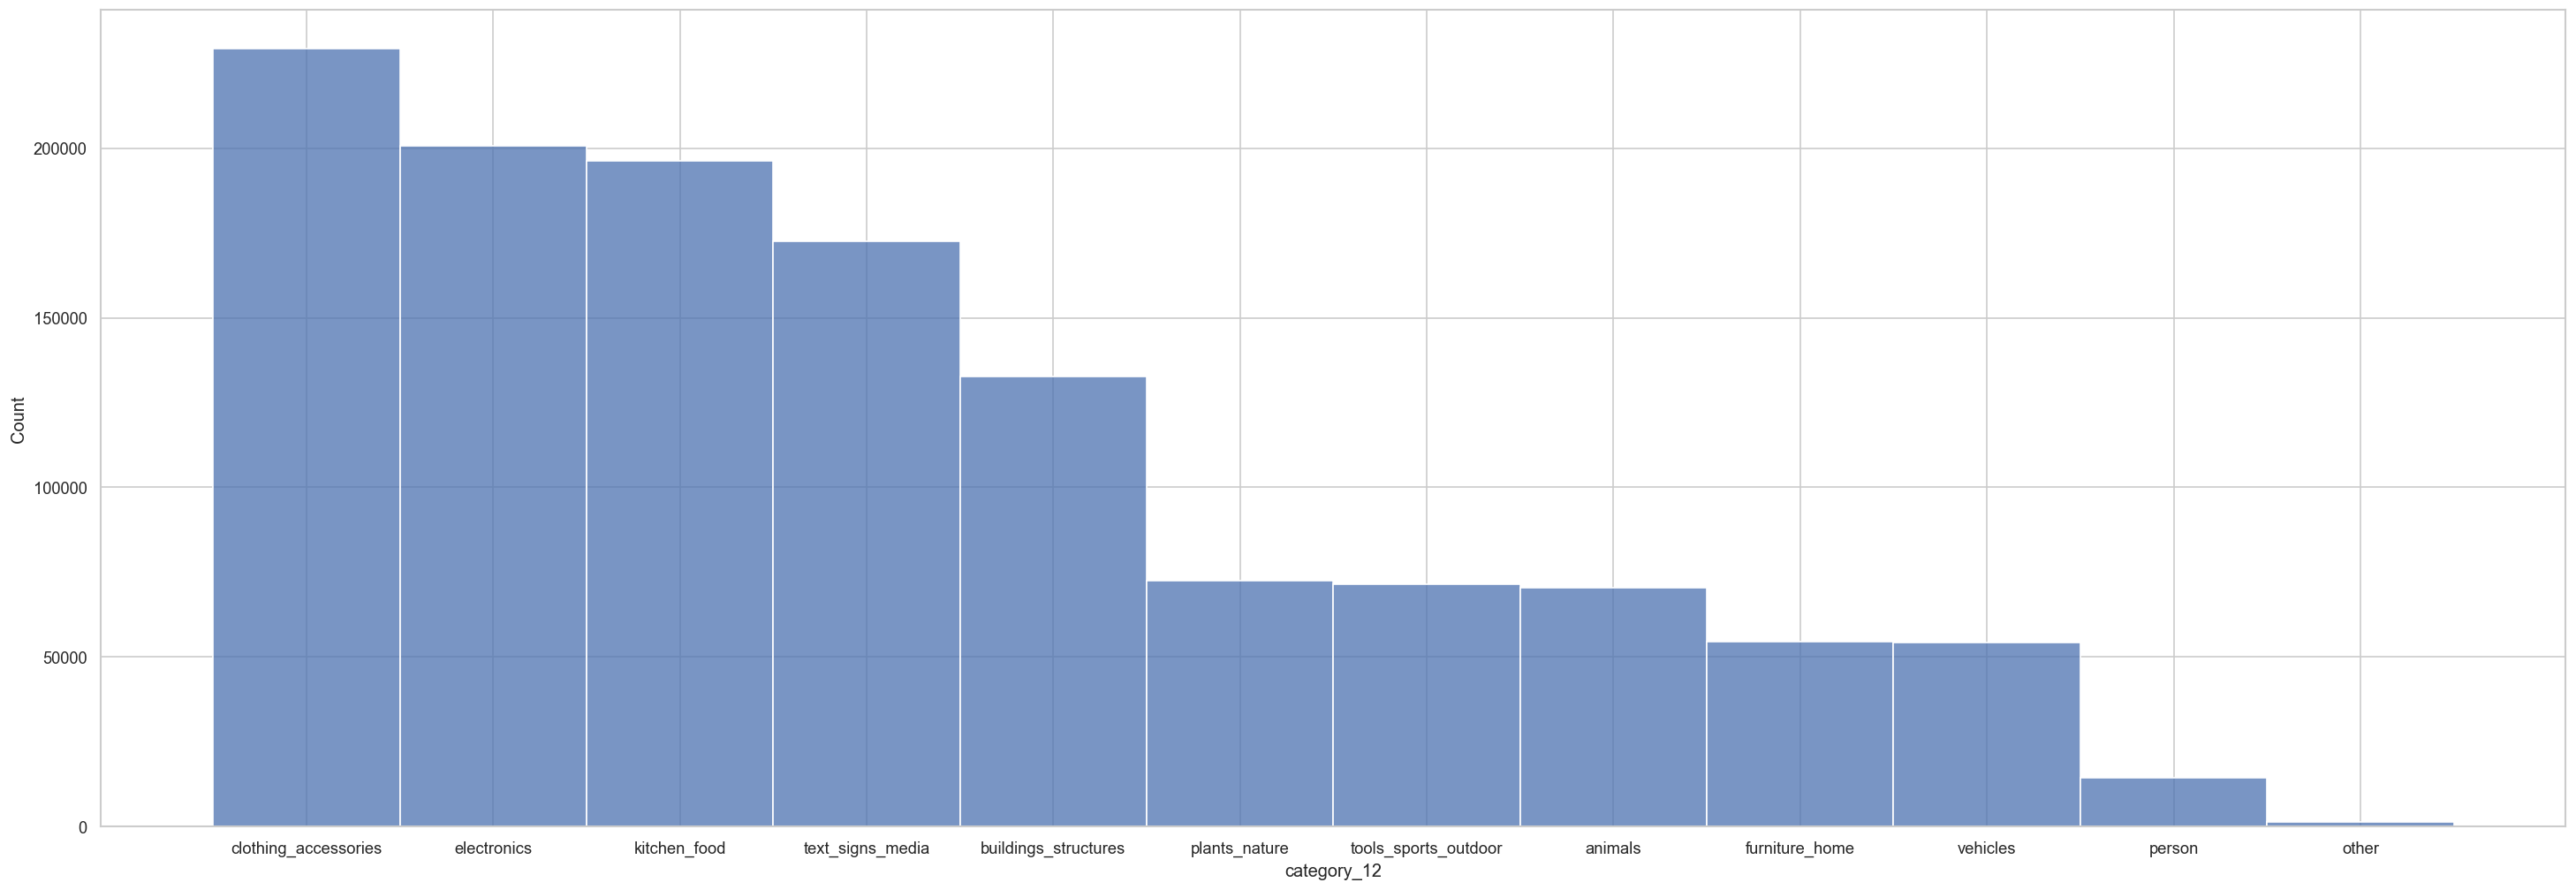

In [48]:
plt.figure(figsize=(30, 10))

order = df["category_12"].value_counts().index.tolist()
plot_df = df.copy()
plot_df["category_12"] = pd.Categorical(
    plot_df["category_12"], categories=order, ordered=True
)

plt.figure(figsize=(30, 10), dpi=120)
ax = sb.histplot(data=plot_df, x="category_12", discrete=True)

#### **Decision**

### **Stratification Strategy & Rules**

To ensure rigorous, unbiased benchmarking across all interactive segmentation methods (GrabCut, Otsu, MobileSAM, SAM 2, YOLOv11-seg), the dataset is stratified under 5 core principles:

1. **Object Scale (COCO Area Thresholds)**:
   - **Small** (`area < 32² px` / `< 1,024 px²`): Target ~20% (tests sensitivity to fine details, distant items, and thin contours).
   - **Medium** (`32² <= area <= 96² px` / `1,024 - 9,216 px²`): Target ~40% (standard objects like chairs, laptops, pets).
   - **Large** (`area > 96² px` / `> 9,216 px²`): Target ~40% (foreground persons, cars, tables).

2. **Bounding Box Aspect Ratio ($AR = \text{width} / \text{height}$)**:
   - **Tall / Slender** ($AR < 0.5$): Target ~25% (standing persons, bottles, poles — challenges box-prompted models with background inclusion).
   - **Square / Balanced** ($0.5 \le AR \le 2.0$): Target ~50% (faces, clocks, sports balls, chairs).
   - **Wide / Elongated** ($AR > 2.0$): Target ~25% (cars, horizontal banners, desks, sleeping animals).

3. **Scene Clutter / Object Density (Annotations per Image)**:
   - **Isolated / Clean** (1 object per image): Target ~30% (baseline unoccluded segmentation performance).
   - **Moderate** (2 to 4 objects per image): Target ~50% (standard interactive settings where target must be distinguished from a few neighbors).
   - **Crowded / Complex** (5 to 10 objects per image): Target ~20% (stress tests boundary leakage and instance confusion).
   - *Exclusion Rule*: Images with $> 10$ annotations or `iscrowd == 1` are excluded to avoid ambiguous polygon labels.

4. **Semantic Class Diversity & Hard Frequency Cap**:
   - **Class Frequency Cap**: No single fine-grained class can exceed **15%** of the sample.
   - **12 Super-Categories**: `person` represents 10%–15% (~12%), while the remaining 11 super-categories share the remaining 88% equally (~8.0% each).

5. **Image Maximization & Dynamic Sizing**:
   - Exactly **1 target annotation is selected per image**, ensuring $N_{\text{images}} = N_{\text{samples}}$ for maximum visual diversity.
   - **Uncapped / Configurable Capacity**: The dataset is calculated up to the maximum feasible balanced capacity (**8,641 unique images**). You can select **any number of rows** you want (e.g., 500, 1,000, 2,500, 5,000, or the full maximum).

In [49]:
# ---------------------------------------------------------------------------
# 1. Feature Engineering & Quality Filtering for Stratification
# ---------------------------------------------------------------------------
# Calculate annotations per image (Scene Clutter)
anno_counts = df["image_id"].value_counts()
df["num_annotations"] = df["image_id"].map(anno_counts)

# Filter out extreme clutter (>10 instances) and crowd annotations (iscrowd == 1)
clean_mask = df["num_annotations"] <= 10
if "iscrowd" in df.columns:
    clean_mask &= (df["iscrowd"] != 1)
df_clean = df[clean_mask].copy()

# Derive Scene Clutter Tiers: Isolated (1), Moderate (2-4), Crowded (5-10)
def get_clutter_tier(n):
    if n == 1: return "isolated"
    elif 2 <= n <= 4: return "moderate"
    else: return "crowded"

df_clean["clutter_tier"] = df_clean["num_annotations"].apply(get_clutter_tier)

# Derive Object Scale Tiers (Standard COCO Thresholds)
# Small (< 32² px), Medium (32² to 96² px), Large (> 96² px)
def get_area_tier(area):
    if area < 32**2: return "small"
    elif area <= 96**2: return "medium"
    else: return "large"

df_clean["area_tier"] = df_clean["area"].apply(get_area_tier)

# Derive Bounding Box Aspect Ratio (width / height of object bbox [x, y, w, h])
# Tall / Slender (< 0.5), Square / Balanced (0.5 to 2.0), Wide / Elongated (> 2.0)
def get_ar_tier(bbox):
    try:
        if isinstance(bbox, str):
            import ast
            bbox = ast.literal_eval(bbox)
        w, h = float(bbox[2]), float(bbox[3])
        if h <= 0: return "square_balanced", 1.0
        ar = w / h
        if ar < 0.5: return "tall_slender", round(ar, 4)
        elif ar <= 2.0: return "square_balanced", round(ar, 4)
        else: return "wide_elongated", round(ar, 4)
    except Exception:
        return "square_balanced", 1.0

ar_results = df_clean["bbox"].apply(get_ar_tier)
df_clean["ar_tier"] = [r[0] for r in ar_results]
df_clean["obj_aspect_ratio"] = [r[1] for r in ar_results]

print(f"Eligible candidate annotations: {len(df_clean):,}")
print(f"Unique eligible images available: {df_clean['image_id'].nunique():,}")


Eligible candidate annotations: 287,877
Unique eligible images available: 63,916


In [50]:
# ---------------------------------------------------------------------------
# 2. Multi-Objective Stratification Algorithm (Dynamic Sample Sizing)
# Maximizes unique images (1 instance per image) while satisfying all 4
# stratification dimensions and class caps.
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd

TARGET_PROPORTIONS = {
    "clutter_tier": {"isolated": 0.30, "moderate": 0.50, "crowded": 0.20},
    "area_tier": {"small": 0.20, "medium": 0.40, "large": 0.40},
    "ar_tier": {"tall_slender": 0.25, "square_balanced": 0.50, "wide_elongated": 0.25},
    "category_12": {
        "person": 0.12,
        **{c: (1.0 - 0.12) / 11 for c in TARGET_SYNSET_GROUPS if c != "person"}
    }
}

def stratify_dataset(
    data: pd.DataFrame,
    target_n=None,
    random_state: int = 42,
    class_cap: float = 0.15,
    person_target: float = 0.12
) -> pd.DataFrame:
    """
    Selects `target_n` samples from `data` satisfying:
    - Exactly 1 annotation per unique image (N_images = target_n).
    - COCO Area scale: 20% small, 40% medium, 40% large.
    - Object Aspect Ratio: 25% tall, 50% square, 25% wide.
    - Scene Clutter: 30% isolated, 50% moderate, 20% crowded.
    - 12 Super-categories: person at person_target (~12%), remaining 11 equal (~8% each).
    - Fine-grained class cap: <= class_cap (15%).
    
    If target_n is None or 'max', automatically calculates the maximum possible
    balanced sample size across all available images.
    """
    rng = np.random.RandomState(random_state)
    
    targets = {
        "clutter_tier": {"isolated": 0.30, "moderate": 0.50, "crowded": 0.20},
        "area_tier": {"small": 0.20, "medium": 0.40, "large": 0.40},
        "ar_tier": {"tall_slender": 0.25, "square_balanced": 0.50, "wide_elongated": 0.25},
        "category_12": {
            "person": person_target,
            **{c: (1.0 - person_target) / 11 for c in TARGET_SYNSET_GROUPS if c != "person"}
        }
    }
    
    # Fast candidate record lookup
    cols = ["image_id", "name", "clutter_tier", "area_tier", "ar_tier", "category_12"]
    data_records = data[cols].to_dict("index")
    
    cat_to_indices = {}
    for idx, rec in data_records.items():
        cat = rec["category_12"]
        if cat not in cat_to_indices:
            cat_to_indices[cat] = []
        cat_to_indices[cat].append(idx)
        
    for cat in cat_to_indices:
        rng.shuffle(cat_to_indices[cat])
        
    cat_order = sorted(cat_to_indices.keys(), key=lambda c: len(cat_to_indices[c]))
    
    # Automatically compute max balanced capacity if target_n is None or 'max'
    if target_n is None or str(target_n).lower() == "max":
        img_per_cat = {cat: len(set(data_records[i]["image_id"] for i in indices)) for cat, indices in cat_to_indices.items()}
        max_possible_cat = min(int(img_per_cat[c] / targets["category_12"][c]) for c in targets["category_12"])
        img_per_clutter = {tier: len(data[data["clutter_tier"] == tier]["image_id"].unique()) for tier in targets["clutter_tier"]}
        max_possible_clutter = min(int(img_per_clutter[t] / targets["clutter_tier"][t]) for t in targets["clutter_tier"])
        target_n = min(max_possible_cat, max_possible_clutter)
        print(f"[Dynamic Capacity] Maximum balanced dataset size: {target_n:,} unique images")
    else:
        target_n = int(target_n)
        print(f"[Target Selected] Sampling requested size: {target_n:,} unique images")
        
    target_counts = {
        dim: {k: int(round(v * target_n)) for k, v in t.items()}
        for dim, t in targets.items()
    }
    for dim, d_targets in target_counts.items():
        diff = target_n - sum(d_targets.values())
        if diff != 0:
            largest_k = max(d_targets, key=d_targets.get)
            d_targets[largest_k] += diff
            
    max_class_allowed = max(1, int(round(class_cap * target_n)))
    current_counts = {dim: {k: 0 for k in t} for dim, t in targets.items()}
    class_counts = {}
    
    selected_indices = []
    selected_images = set()
    
    # Multi-pass matching per category
    for cat in cat_order:
        needed = target_counts["category_12"][cat]
        candidates = cat_to_indices[cat]
        is_rare = (cat in ["person", "other"])
        
        for pass_num in [1, 2, 3]:
            if current_counts["category_12"][cat] >= needed:
                break
            if len(selected_indices) >= target_n:
                break
                
            for idx in candidates:
                if current_counts["category_12"][cat] >= needed:
                    break
                if len(selected_indices) >= target_n:
                    break
                    
                rec = data_records[idx]
                img_id = rec["image_id"]
                if img_id in selected_images:
                    continue
                    
                c_name = rec["name"]
                if class_counts.get(c_name, 0) >= max_class_allowed:
                    continue
                    
                c_val = rec["clutter_tier"]
                a_val = rec["area_tier"]
                r_val = rec["ar_tier"]
                
                c_rem = target_counts["clutter_tier"][c_val] - current_counts["clutter_tier"][c_val]
                a_rem = target_counts["area_tier"][a_val] - current_counts["area_tier"][a_val]
                r_rem = target_counts["ar_tier"][r_val] - current_counts["ar_tier"][r_val]
                
                if pass_num == 1:
                    if c_rem <= 0 or a_rem <= 0 or r_rem <= 0:
                        continue
                elif pass_num == 2:
                    if is_rare:
                        if c_rem < -max(10, int(0.02 * target_n)): continue
                    else:
                        if c_rem <= 0: continue
                    if a_rem <= 0 and r_rem <= 0:
                        continue
                else: # pass 3
                    if is_rare:
                        if c_rem < -max(20, int(0.04 * target_n)): continue
                    else:
                        if c_rem <= 0: continue
                        
                selected_indices.append(idx)
                selected_images.add(img_id)
                class_counts[c_name] = class_counts.get(c_name, 0) + 1
                current_counts["clutter_tier"][c_val] += 1
                current_counts["area_tier"][a_val] += 1
                current_counts["ar_tier"][r_val] += 1
                current_counts["category_12"][cat] += 1

    # Fill any remaining slots
    if len(selected_indices) < target_n:
        all_indices = list(data_records.keys())
        rng.shuffle(all_indices)
        for idx in all_indices:
            if len(selected_indices) >= target_n:
                break
            rec = data_records[idx]
            img_id = rec["image_id"]
            if img_id in selected_images:
                continue
            c_name = rec["name"]
            if class_counts.get(c_name, 0) >= max_class_allowed:
                continue
            selected_indices.append(idx)
            selected_images.add(img_id)
            class_counts[c_name] = class_counts.get(c_name, 0) + 1
            current_counts["clutter_tier"][rec["clutter_tier"]] += 1
            current_counts["area_tier"][rec["area_tier"]] += 1
            current_counts["ar_tier"][rec["ar_tier"]] += 1
            current_counts["category_12"][rec["category_12"]] += 1
            
    sample_df = data.loc[selected_indices].copy().reset_index(drop=True)
    return sample_df


In [51]:
# ===========================================================================
# USER CONFIGURATION: CHOOSE THE AMOUNT OF ROWS YOU WANT
# ===========================================================================
# Set to an integer (e.g., 500, 1000, 2500, 5000) or None / "max" to keep the FULL maximal dataset:
DESIRED_SAMPLE_SIZE = 1000  # <-- Change this to any amount of rows you want (or None for all!)

stratified_df = stratify_dataset(
    df_clean,
    target_n=DESIRED_SAMPLE_SIZE,
    random_state=42,
    class_cap=0.15
)

print(f"\nSuccessfully extracted {len(stratified_df):,} rows across {stratified_df['image_id'].nunique():,} unique images.")
assert stratified_df['image_id'].nunique() == len(stratified_df), "Error: Duplicate images detected!"

# Build Audit Comparison Table
audit_rows = []
for dim, targets in TARGET_PROPORTIONS.items():
    actual_counts = stratified_df[dim].value_counts()
    actual_props = stratified_df[dim].value_counts(normalize=True)
    for tier, target_prop in targets.items():
        cnt = actual_counts.get(tier, 0)
        act_p = actual_props.get(tier, 0.0)
        audit_rows.append({
            "Dimension": dim,
            "Tier / Category": tier,
            "Actual Count": cnt,
            "Actual %": f"{act_p * 100:.2f}%",
            "Target %": f"{target_prop * 100:.2f}%",
            "Difference": f"{(act_p - target_prop) * 100:+.2f}%"
        })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

top_class = stratified_df["name"].value_counts().index[0]
top_class_prop = stratified_df["name"].value_counts(normalize=True).iloc[0]
print(f"\nDominant Fine-grained Class: '{top_class}' representing {top_class_prop * 100:.2f}% of samples (Cap: <= 15.00%)")


[Target Selected] Sampling requested size: 1,000 unique images

Successfully extracted 1,000 rows across 1,000 unique images.


,Dimension,Tier / Category,Actual Count,Actual %,Target %,Difference
0,clutter_tier,isolated,300,30.00%,30.00%,+0.00%
1,clutter_tier,moderate,500,50.00%,50.00%,+0.00%
2,clutter_tier,crowded,200,20.00%,20.00%,+0.00%
3,area_tier,small,200,20.00%,20.00%,+0.00%
4,area_tier,medium,400,40.00%,40.00%,+0.00%
5,area_tier,large,400,40.00%,40.00%,+0.00%
6,ar_tier,tall_slender,250,25.00%,25.00%,+0.00%
7,ar_tier,square_balanced,500,50.00%,50.00%,+0.00%
8,ar_tier,wide_elongated,250,25.00%,25.00%,+0.00%
9,category_12,person,120,12.00%,12.00%,+0.00%



Dominant Fine-grained Class: 'person' representing 11.30% of samples (Cap: <= 15.00%)


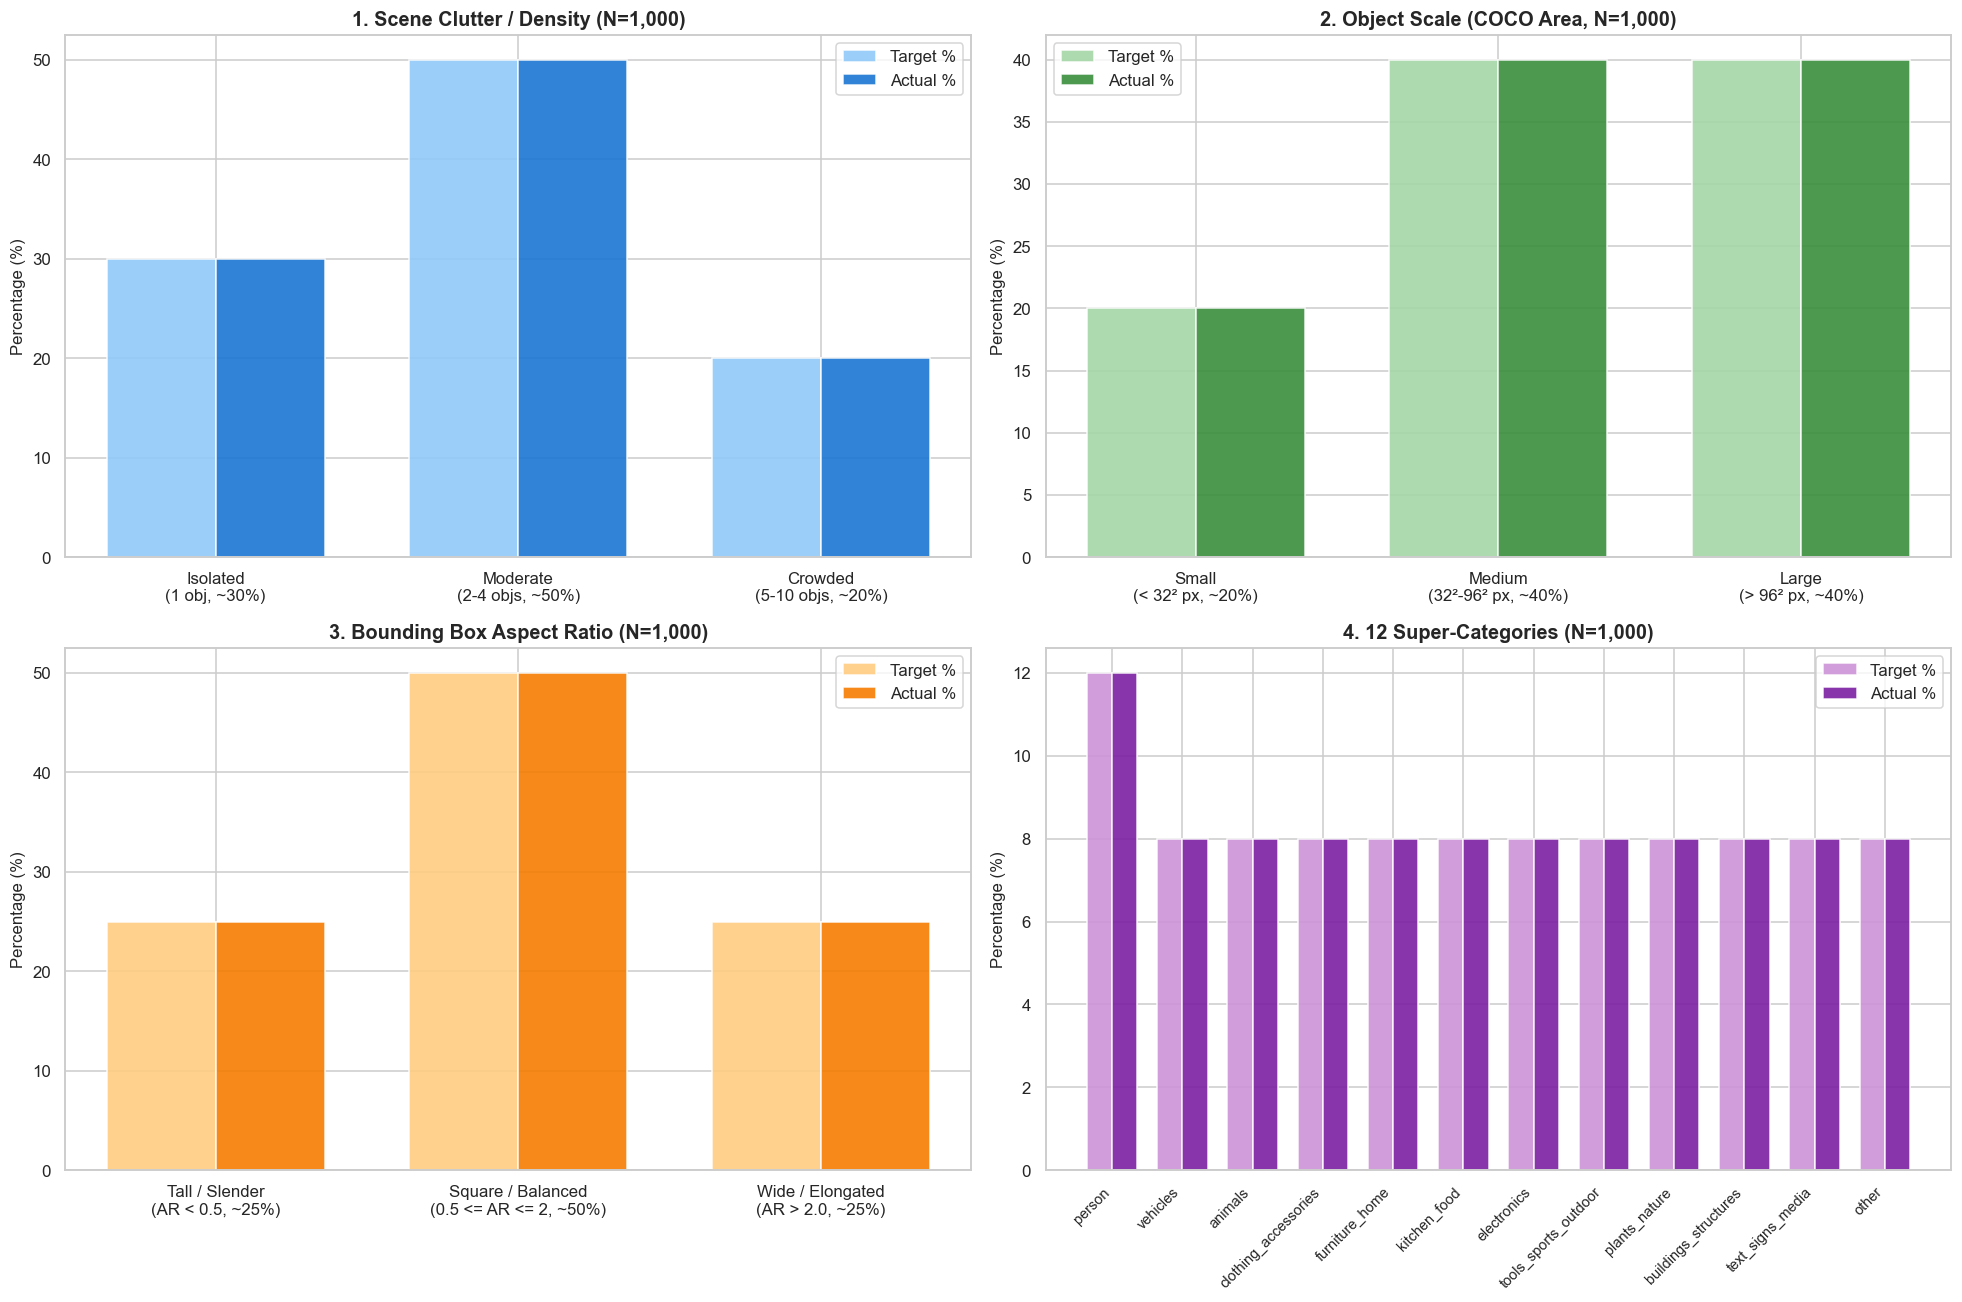

In [52]:
# ---------------------------------------------------------------------------
# 4. Visual Validation: Actual vs Target Distributions Across 4 Dimensions
# ---------------------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sb

sb.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(2, 2, figsize=(18, 12), dpi=110)

# 1. Scene Clutter
clutter_order = ["isolated", "moderate", "crowded"]
clutter_actual = stratified_df["clutter_tier"].value_counts(normalize=True).reindex(clutter_order) * 100
clutter_target = [30.0, 50.0, 20.0]
x_clutter = np.arange(len(clutter_order))
axes[0, 0].bar(x_clutter - 0.18, clutter_target, width=0.36, label="Target %", color="#90caf9", alpha=0.9)
axes[0, 0].bar(x_clutter + 0.18, clutter_actual, width=0.36, label="Actual %", color="#1976d2", alpha=0.9)
axes[0, 0].set_xticks(x_clutter)
axes[0, 0].set_xticklabels(["Isolated\n(1 obj, ~30%)", "Moderate\n(2-4 objs, ~50%)", "Crowded\n(5-10 objs, ~20%)"], fontsize=11)
axes[0, 0].set_title(f"1. Scene Clutter / Density (N={len(stratified_df):,})", fontsize=13, fontweight="bold")
axes[0, 0].set_ylabel("Percentage (%)", fontsize=11)
axes[0, 0].legend()

# 2. Object Area Scale
area_order = ["small", "medium", "large"]
area_actual = stratified_df["area_tier"].value_counts(normalize=True).reindex(area_order) * 100
area_target = [20.0, 40.0, 40.0]
x_area = np.arange(len(area_order))
axes[0, 1].bar(x_area - 0.18, area_target, width=0.36, label="Target %", color="#a5d6a7", alpha=0.9)
axes[0, 1].bar(x_area + 0.18, area_actual, width=0.36, label="Actual %", color="#388e3c", alpha=0.9)
axes[0, 1].set_xticks(x_area)
axes[0, 1].set_xticklabels(["Small\n(< 32² px, ~20%)", "Medium\n(32²-96² px, ~40%)", "Large\n(> 96² px, ~40%)"], fontsize=11)
axes[0, 1].set_title(f"2. Object Scale (COCO Area, N={len(stratified_df):,})", fontsize=13, fontweight="bold")
axes[0, 1].set_ylabel("Percentage (%)", fontsize=11)
axes[0, 1].legend()

# 3. Aspect Ratio
ar_order = ["tall_slender", "square_balanced", "wide_elongated"]
ar_actual = stratified_df["ar_tier"].value_counts(normalize=True).reindex(ar_order) * 100
ar_target = [25.0, 50.0, 25.0]
x_ar = np.arange(len(ar_order))
axes[1, 0].bar(x_ar - 0.18, ar_target, width=0.36, label="Target %", color="#ffcc80", alpha=0.9)
axes[1, 0].bar(x_ar + 0.18, ar_actual, width=0.36, label="Actual %", color="#f57c00", alpha=0.9)
axes[1, 0].set_xticks(x_ar)
axes[1, 0].set_xticklabels(["Tall / Slender\n(AR < 0.5, ~25%)", "Square / Balanced\n(0.5 <= AR <= 2, ~50%)", "Wide / Elongated\n(AR > 2.0, ~25%)"], fontsize=11)
axes[1, 0].set_title(f"3. Bounding Box Aspect Ratio (N={len(stratified_df):,})", fontsize=13, fontweight="bold")
axes[1, 0].set_ylabel("Percentage (%)", fontsize=11)
axes[1, 0].legend()

# 4. Super-categories
cat_order = list(TARGET_PROPORTIONS["category_12"].keys())
cat_actual = stratified_df["category_12"].value_counts(normalize=True).reindex(cat_order) * 100
cat_target = [TARGET_PROPORTIONS["category_12"][c] * 100 for c in cat_order]
x_cat = np.arange(len(cat_order))
axes[1, 1].bar(x_cat - 0.18, cat_target, width=0.36, label="Target %", color="#ce93d8", alpha=0.9)
axes[1, 1].bar(x_cat + 0.18, cat_actual, width=0.36, label="Actual %", color="#7b1fa2", alpha=0.9)
axes[1, 1].set_xticks(x_cat)
axes[1, 1].set_xticklabels(cat_order, rotation=45, ha="right", fontsize=9.5)
axes[1, 1].set_title(f"4. 12 Super-Categories (N={len(stratified_df):,})", fontsize=13, fontweight="bold")
axes[1, 1].set_ylabel("Percentage (%)", fontsize=11)
axes[1, 1].legend()

plt.tight_layout()
plt.show()


In [53]:
# ---------------------------------------------------------------------------
# 5. Export Stratified Dataset for Benchmarking
# ---------------------------------------------------------------------------
output_csv_path = "lvis_stratified_dataset_1000.csv"
stratified_df.to_csv(output_csv_path, index=False)
print(f"Successfully saved {len(stratified_df):,} stratified rows to '{output_csv_path}'")
stratified_df[["image_id", "name", "category_12", "clutter_tier", "area_tier", "ar_tier", "obj_aspect_ratio"]].head(10)


Successfully saved 1,000 stratified rows to 'lvis_stratified_dataset_1000.csv'


,image_id,name,category_12,clutter_tier,area_tier,ar_tier,obj_aspect_ratio
0,199028,stop_sign,other,moderate,large,square_balanced,0.7272
1,291773,stop_sign,other,crowded,large,tall_slender,0.4208
2,357290,stop_sign,other,crowded,large,tall_slender,0.2311
3,425381,stop_sign,other,moderate,large,square_balanced,0.8835
4,433225,stop_sign,other,crowded,medium,square_balanced,0.9245
5,197300,stop_sign,other,crowded,large,square_balanced,1.2015
6,122589,stop_sign,other,moderate,medium,square_balanced,0.9825
7,398407,stop_sign,other,crowded,large,square_balanced,0.9919
8,251183,stop_sign,other,isolated,medium,square_balanced,0.9393
9,97363,stop_sign,other,isolated,medium,square_balanced,0.5095


### **Export to Parquet Dataset with Embedded Image Data**

To provide a self-contained, high-performance dataset for benchmarking and training, the code below downloads the raw image data from `coco_url` and embeds it directly into an Apache Parquet file (`lvis_stratified_dataset.parquet`).

- **Embedded Column**: `image_data` stores the raw binary JPEG bytes (`bytes`).
- **High-Speed Multithreading**: Downloads images concurrently using `ThreadPoolExecutor` and connection pooling.
- **Zero Quality Loss & Fast I/O**: Retains original image compression (~120–150 KB per image) and loads instantly via `PIL.Image.open(io.BytesIO(row['image_data']))` or OpenCV.

Successfully downloaded 1,000 / 1,000 images.

Successfully exported Parquet dataset to: 'lvis_stratified_dataset_1000.parquet' (147.60 MB)
Parquet Schema: 31 columns, 1,000 rows with embedded 'image_data'.


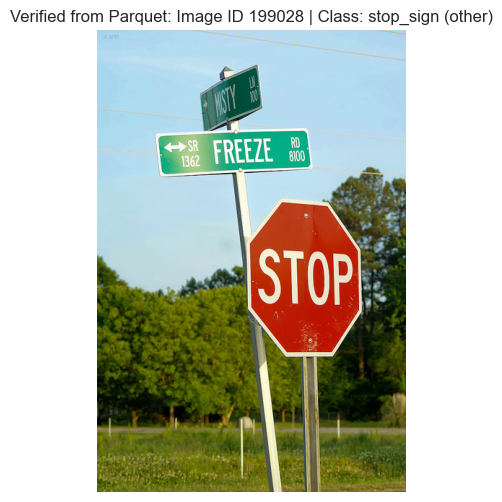

In [54]:
# ---------------------------------------------------------------------------
# 6. Download Images from 'coco_url' & Export to Parquet
# ---------------------------------------------------------------------------
import io
import os
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# 1. Setup persistent HTTP session with connection pooling and retries
session = requests.Session()
adapter = requests.adapters.HTTPAdapter(pool_connections=32, pool_maxsize=32, max_retries=3)
session.mount("http://", adapter)
session.mount("https://", adapter)

# 2. Image Downloader Function
def fetch_image_bytes(row_tuple):
    idx, url = row_tuple
    try:
        resp = session.get(url, timeout=15)
        if resp.status_code == 200:
            return idx, resp.content
    except Exception:
        pass
    return idx, None

# 3. Execute Concurrent Image Downloads
print(f"Downloading images for {len(stratified_df):,} stratified samples using concurrent workers...")
tasks = list(zip(stratified_df.index, stratified_df["coco_url"]))
downloaded_bytes = [None] * len(stratified_df)
idx_to_pos = {idx: i for i, idx in enumerate(stratified_df.index)}

with ThreadPoolExecutor(max_workers=20) as executor:
    futures = [executor.submit(fetch_image_bytes, t) for t in tasks]
    for f in tqdm(as_completed(futures), total=len(futures), desc="Downloading COCO images"):
        idx, content = f.result()
        pos = idx_to_pos[idx]
        downloaded_bytes[pos] = content

# 4. Embed image_data column into DataFrame
stratified_parquet_df = stratified_df.copy()
stratified_parquet_df["image_data"] = downloaded_bytes

success_count = sum(1 for b in downloaded_bytes if b is not None)
print(f"Successfully downloaded {success_count:,} / {len(stratified_df):,} images.")

# 5. Export to Apache Parquet format
output_parquet_path = "lvis_stratified_dataset_1000.parquet"
stratified_parquet_df.to_parquet(output_parquet_path, index=False, engine="pyarrow")

file_size_mb = os.path.getsize(output_parquet_path) / (1024 * 1024)
print(f"\nSuccessfully exported Parquet dataset to: '{output_parquet_path}' ({file_size_mb:.2f} MB)")
print(f"Parquet Schema: {len(stratified_parquet_df.columns)} columns, {len(stratified_parquet_df):,} rows with embedded 'image_data'.")

# 6. Verify by loading a sample directly from Parquet
sample_read = pd.read_parquet(output_parquet_path, columns=["image_id", "name", "category_12", "image_data"])
first_valid = sample_read[sample_read["image_data"].notna()].iloc[0]
verified_img = Image.open(io.BytesIO(first_valid["image_data"]))

plt.figure(figsize=(6, 6))
plt.imshow(verified_img)
plt.title(f"Verified from Parquet: Image ID {first_valid['image_id']} | Class: {first_valid['name']} ({first_valid['category_12']})")
plt.axis("off")
plt.show()
